# OKR v2.1.0 vs. KFG: Cross-Repository Concordance & Schema Audit

This notebook loads the frozen `n = 611` 1-to-1 concordance outputs produced by `src/master_concordance_611.py`, verifies all summary tables and statistical claims, and displays the 4 publication-ready figures generated by `src/make_figures.py`.

In [1]:
import pathlib
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import Image, display

ROOT = pathlib.Path('..').resolve()
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
print('Project root:', ROOT)

Project root: C:\Users\maria\.gemini\antigravity\scratch\khipu-okr-kfg-concordance


## 1. Exact 1-to-1 Corpus Accounting & Specimen-Level Concordance (`n = 611`)

Matched 1-to-1 specimens: 611
match_type
OKR_NUM==okr_name                  593
INVESTIGATOR_NUM==original_name     18


,Field,n,Exact_%,Within_5%,Med_abs_diff,Max_abs_diff,Spearman_r
0,Recto cords,611,97.2,97.4,0.00,185.0,0.9437
1,Verso cords,611,96.1,96.9,0.00,226.0,0.9379
2,Z-twist cords,611,96.9,97.5,0.00,214.0,0.9874
3,Pendant cords,611,93.0,95.7,0.00,337.0,0.9541
4,S-twist cords,611,87.7,89.9,0.00,357.0,0.9210
5,Total cords,611,85.3,87.9,0.00,362.0,0.9414
6,Subsidiary cords (L>1),611,84.0,86.4,0.00,352.0,0.7622
7,Total knots,611,81.0,85.6,0.00,1248.0,0.9176
8,S-dir knots,611,86.3,89.0,0.00,448.0,0.9269
9,Z-dir knots,611,85.6,88.9,0.00,1245.0,0.9592


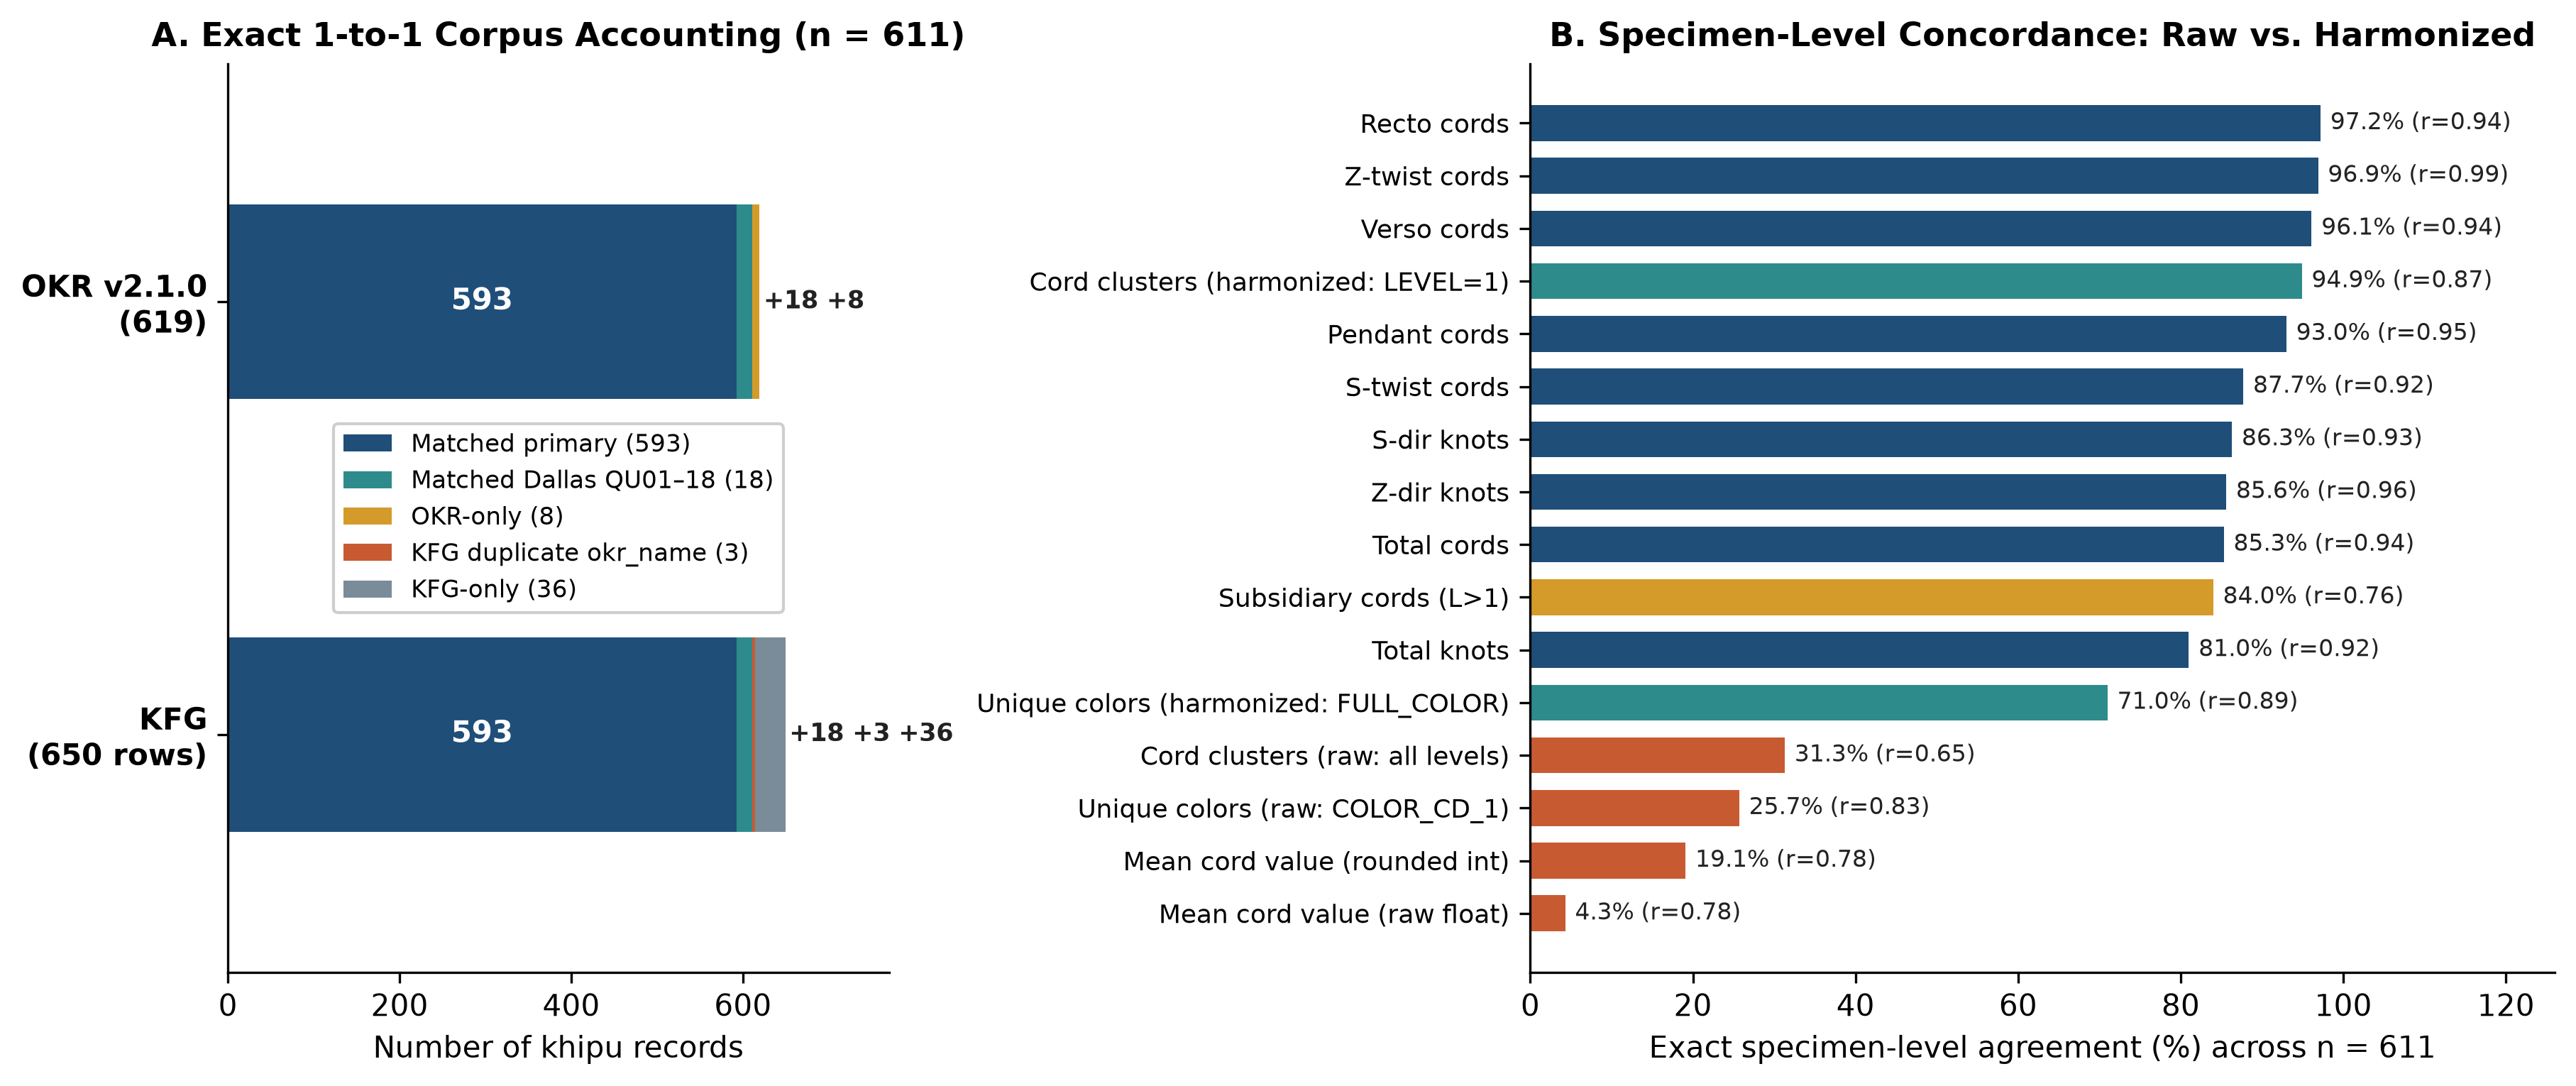

In [2]:
m = pd.read_csv(RESULTS / 'master_matched_611.csv')
t1 = pd.read_csv(RESULTS / 'table1_specimen_concordance_611.csv')
print('Matched 1-to-1 specimens:', len(m))
print(m['match_type'].value_counts().to_string())
display(t1)
display(Image(filename=str(FIGURES / 'fig1_concordance_overview.png'), width=900))

## 2. Silent Subsidiary Drop in KFG `khipu_summary.csv` by OKR Cataloger

Total dropped subsidiary cords: 2,313 / 15,115 (15.3%)


,CREATED_BY,n_with_okr_sub,n_kfg_zero_sub,okr_sub_cords,dropped_sub_cords
0,julia,51,44,2402,1716
1,jclindaniel,20,18,597,593
2,gurton,79,1,2140,4
3,chandra,10,0,1207,0
4,cbrezine,44,0,1667,0
5,Chandra,1,0,77,0
6,eric,31,0,820,0
7,katie,93,0,3202,0
8,leah,40,0,776,0
9,luca,2,0,122,0


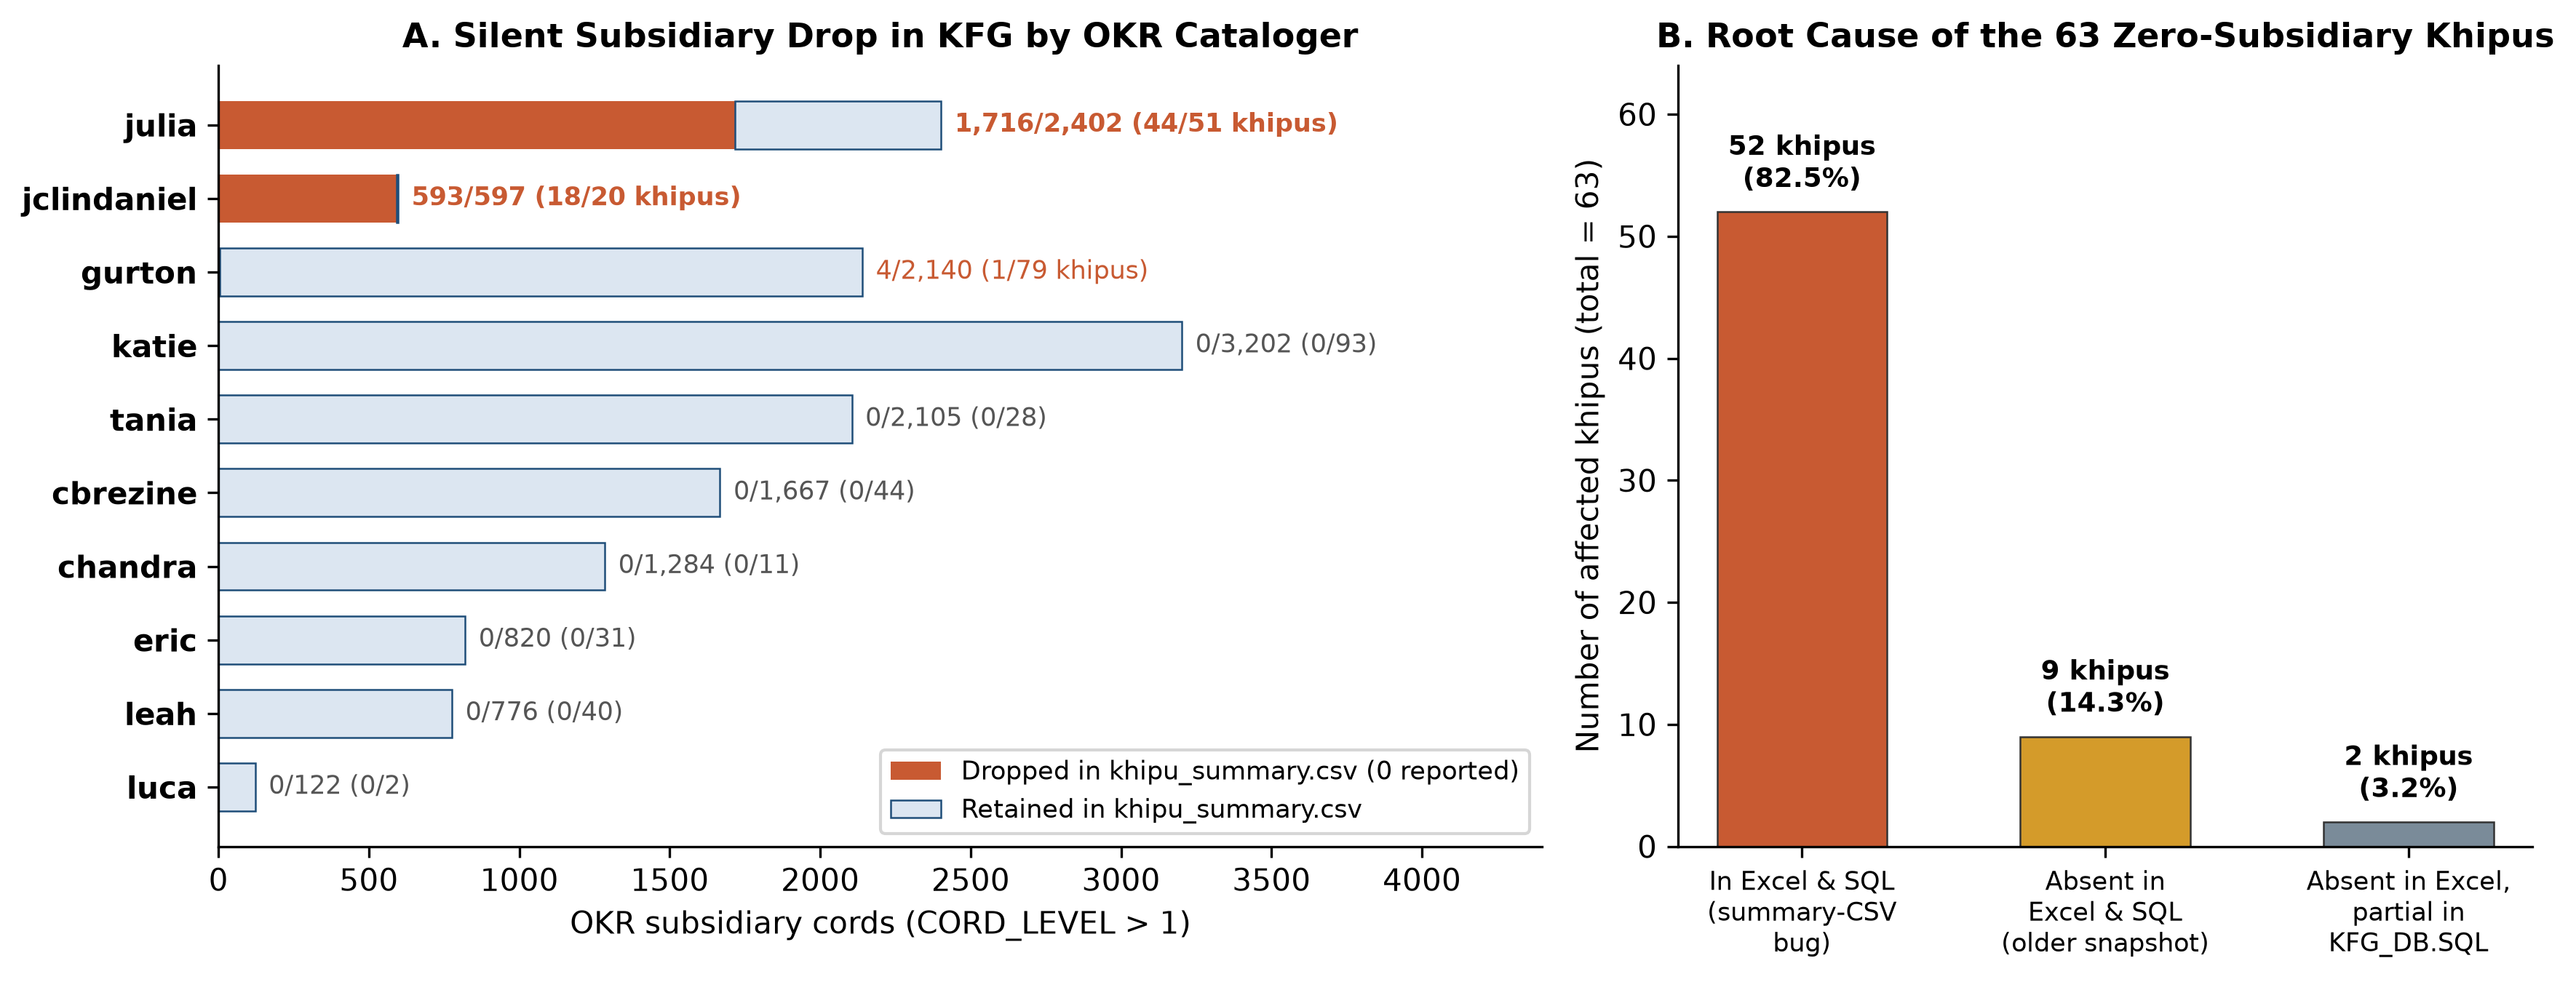

In [3]:
t2 = pd.read_csv(RESULTS / 'table2_subsidiary_drop_611.csv')
print(f"Total dropped subsidiary cords: {t2['dropped_sub_cords'].sum():,} / {t2['okr_sub_cords'].sum():,} ({100*t2['dropped_sub_cords'].sum()/t2['okr_sub_cords'].sum():.1f}%)")
display(t2)
display(Image(filename=str(FIGURES / 'fig2_subsidiary_drop.png'), width=900))

## 3. Cord-by-Cord Multi-Field Benchmark (`33,752` Aligned Pendants, `567` Khipus)

,Field_Subset,n_cords,Exact_%,Mismatches
0,"TWIST (all cords, incl. U)",33752,99.46,181
1,TWIST (both S/Z known),27994,100.00,0
2,"ATTACHMENT (all cords, incl. U)",33752,99.46,181
3,ATTACHMENT (both R/V known),23027,100.00,0
4,"COLOR (FULL_COLOR vs KFG Color, both known)",33154,79.46,6809
5,VALUE (all aligned pendants),33752,81.70,6175
6,"VALUE (unknotted, n_knots==0)",10705,98.91,117
7,"VALUE (knotted, clean decimal)",17933,93.66,1137
8,"VALUE (knotted, non-clean decimal)",5114,3.77,4921


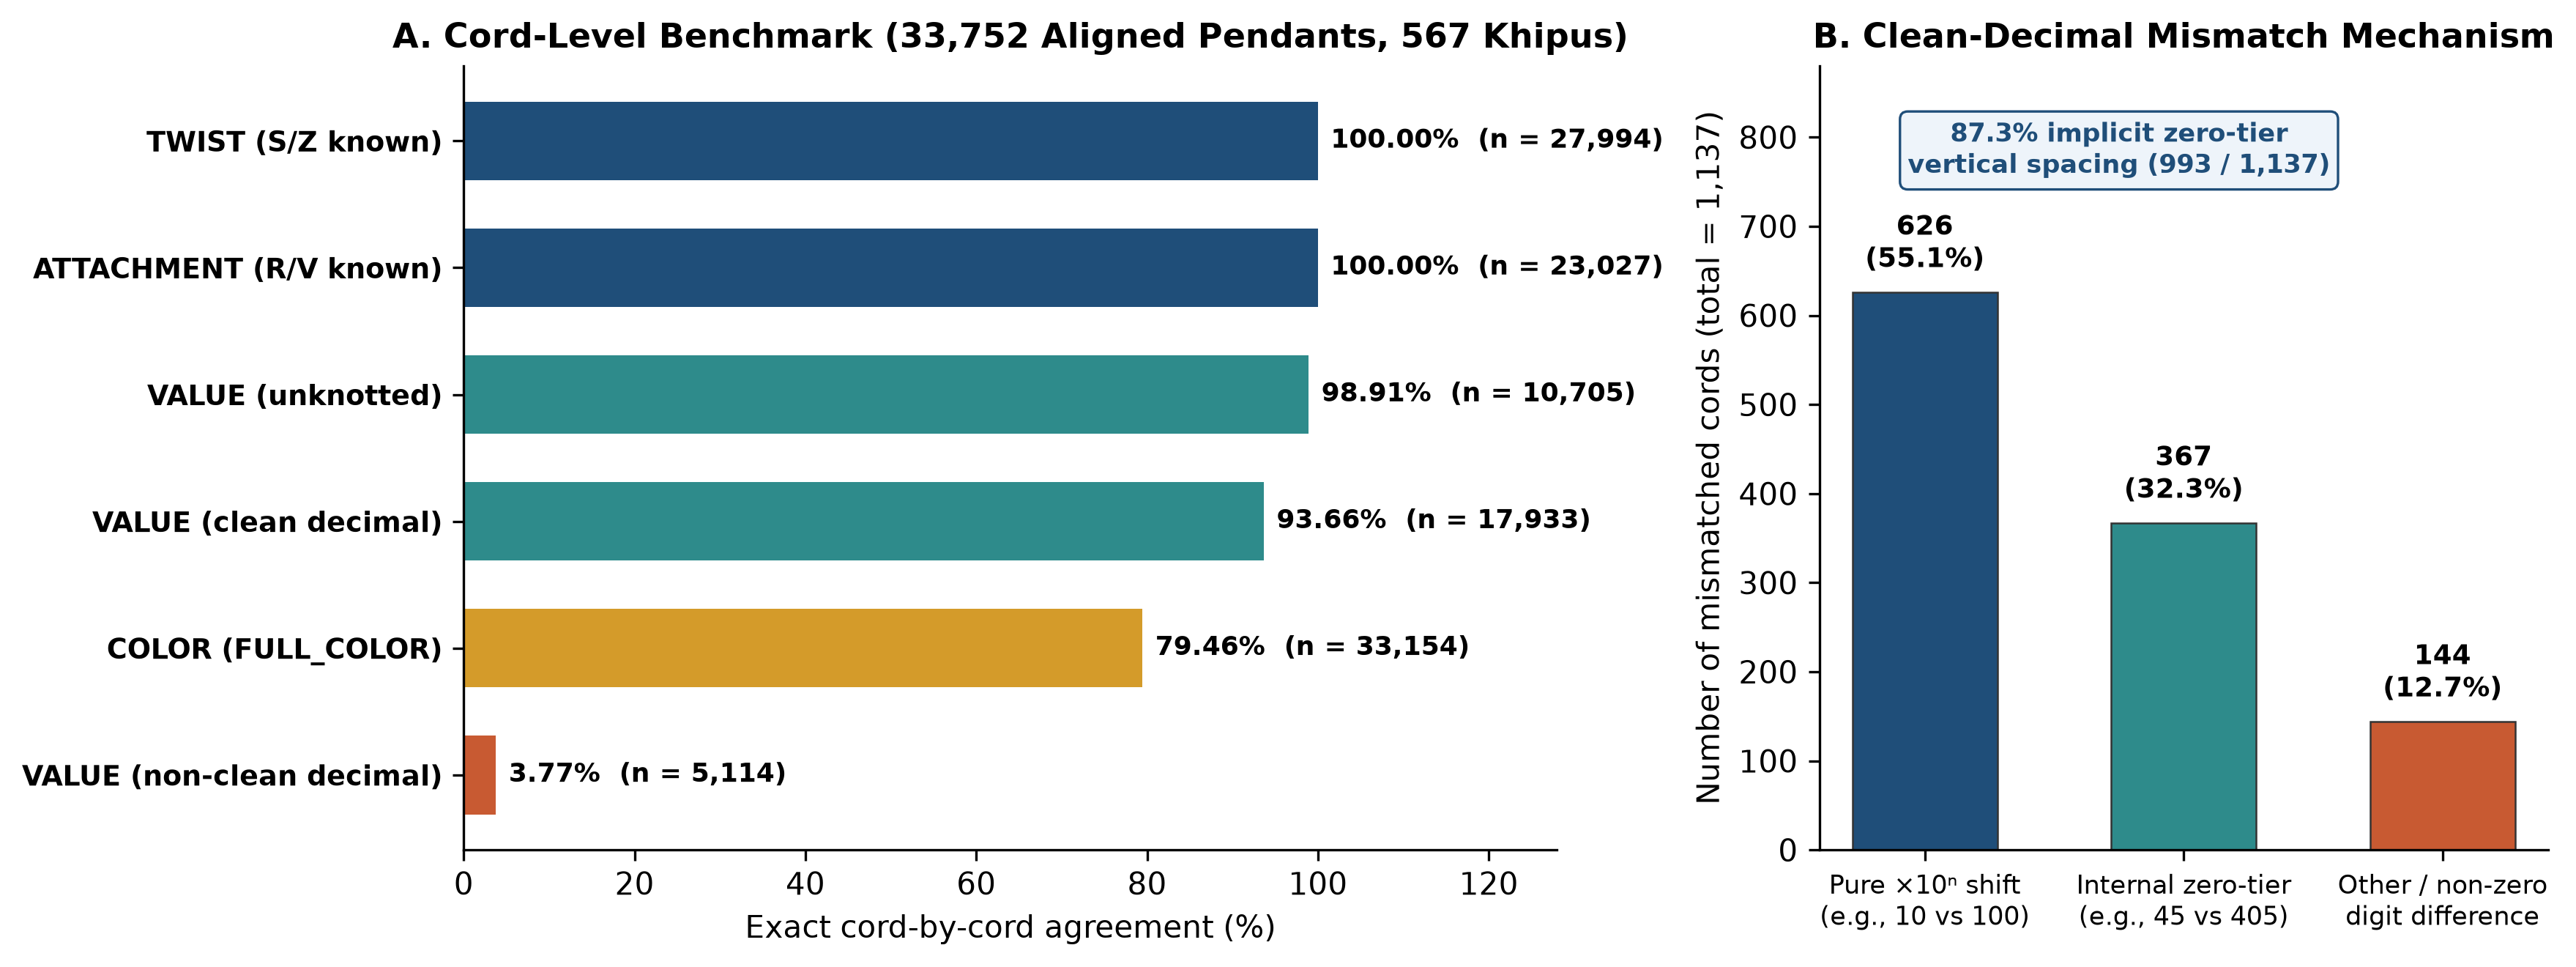

In [4]:
t3 = pd.read_csv(RESULTS / 'table3_cord_level_benchmark_611.csv')
display(t3)
display(Image(filename=str(FIGURES / 'fig3_cord_level_benchmark.png'), width=900))

## 4. Independent Cross-Repository Replication of H3a, H3b & H5c on KFG

,Test,n,Effect_or_Obs,p_specimen,p_museum,OKR_KFG_Spearman
0,KFG H3a (Color homology),312,+0.0862 (70.8% pos),3.84e-32,2.57e-09 (n_m=58),0.9830 (n=295)
1,KFG H3b (Numeric homology),330,+0.4027 (83.3% pos),3.05e-38,1.19e-09 (n_m=58),0.6887 (n=312)
2,KFG H5c (first/last sum),250,45 vs 22.85 (1.97x; 25 khipus),agg p=0.0010 (8 p<0.05),—,—
3,KFG H5c (any-row sum),250,57 vs 41.31 (1.38x),agg p=0.0090,—,—


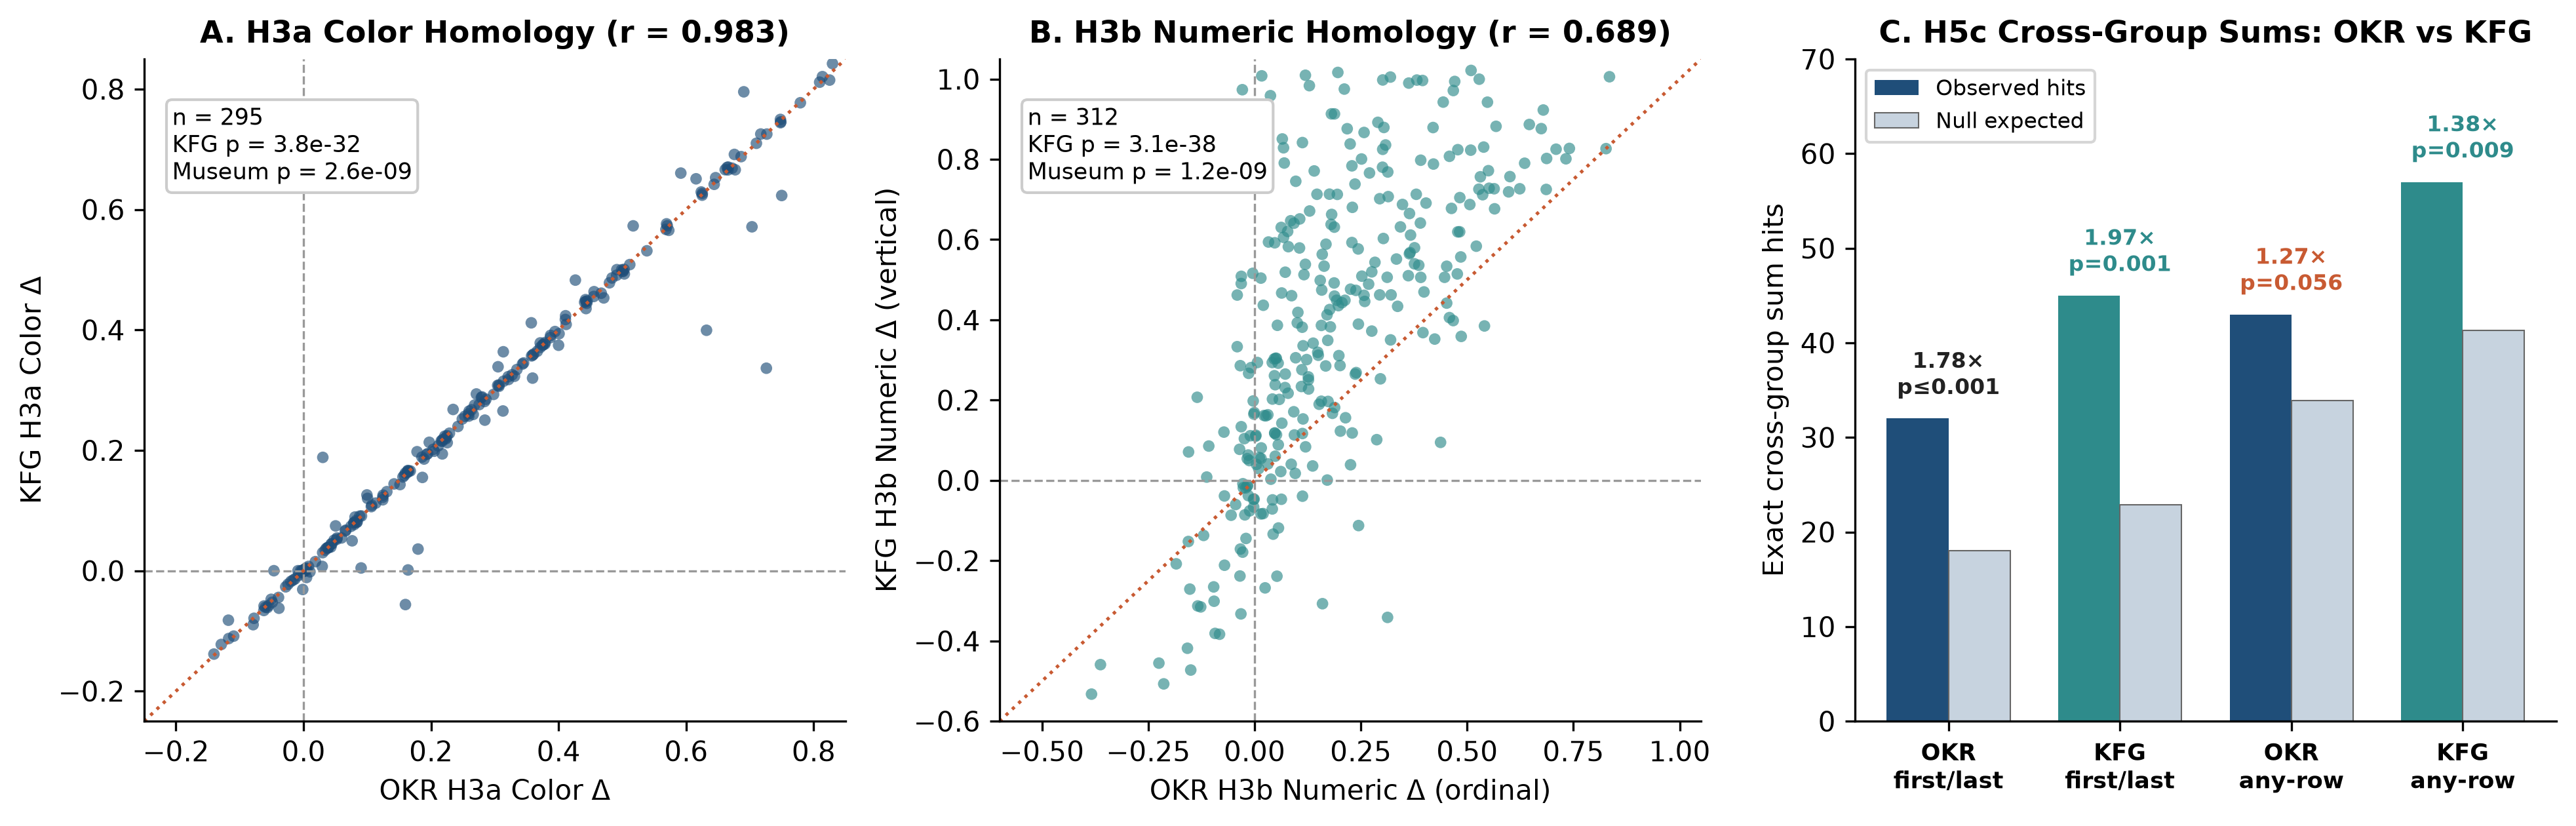

In [5]:
t4 = pd.read_csv(RESULTS / 'table4_kfg_replication_h3_h5c_611.csv')
display(t4)
display(Image(filename=str(FIGURES / 'fig4_kfg_replication_h3_h5c.png'), width=950))